# Automatidata | NYC Taxi Tip Analysis & Classification

**Portfolio adaptation of my Google Advanced Data Analytics coursework.**

**Business problem.** Analyze tip behavior in a 2017 NYC taxi sample and evaluate whether pre-trip information can predict if a card-paid trip will receive a tip of **at least 20%**. This model is an educational experiment, **not** a tool for refusing passengers or making individual service decisions.

**Reproducibility.** This analysis runs using only the original `2017_Yellow_Taxi_Trip_Data.csv` file. The separate `nyc_preds_means.csv` from a previous course was not available, so the features and model below have been deliberately redesigned instead of fabricating that file. Results are not directly comparable with the original Coursera notebook.

## 1. Imports and data validation

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay

DATA = Path('../data/2017_Yellow_Taxi_Trip_Data.csv')
if not DATA.exists():
    DATA = Path('data/2017_Yellow_Taxi_Trip_Data.csv')
df = pd.read_csv(DATA)
print('Rows and columns:', df.shape)
print('Missing values:', df.isna().sum().sum())
display(df.head(3))

Rows and columns: (22699, 18)
Missing values: 0


,Unnamed: 0,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount
0,24870114,2,03/25/2017 8:55:43 AM,03/25/2017 9:09:47 AM,6,3.34,1,N,100,231,1,13.0,0.0,0.5,2.76,0.0,0.3,16.56
1,35634249,1,04/11/2017 2:53:28 PM,04/11/2017 3:19:58 PM,1,1.80,1,N,186,43,1,16.0,0.0,0.5,4.00,0.0,0.3,20.80
2,106203690,1,12/15/2017 7:26:56 AM,12/15/2017 7:34:08 AM,1,1.00,1,N,262,236,1,6.5,0.0,0.5,1.45,0.0,0.3,8.75


## 2. Define the outcome carefully

In this dataset, card payments have recorded tips; cash tips are not reliably observed. We therefore restrict to credit-card payments, positive pre-tip totals, and a nonnegative tip amount. The target is derived strictly from the final outcome and **never used as an input feature**.

In [2]:
work = df.loc[df['payment_type'].eq(1)].copy()
pre_tip_total = work['total_amount'] - work['tip_amount']
work = work.loc[(pre_tip_total > 0) & work['tip_amount'].ge(0)].copy()
work['tip_percent'] = (work['tip_amount'] / (work['total_amount'] - work['tip_amount'])).round(3)
work['generous'] = work['tip_percent'].ge(0.20).astype(int)
work['pickup'] = pd.to_datetime(work['tpep_pickup_datetime'], errors='coerce')
work['pickup_hour'] = work['pickup'].dt.hour
work['pickup_day'] = work['pickup'].dt.dayofweek
work['pickup_month'] = work['pickup'].dt.month
work = work.dropna(subset=['pickup_hour', 'pickup_day', 'pickup_month'])
print('Eligible card-paid trips:', len(work))
print('Target distribution:')
display(work['generous'].value_counts(normalize=True).rename('proportion').to_frame())

Eligible card-paid trips: 15262
Target distribution:


,proportion
generous,
1,0.526471
0,0.473529


## 3. Exploratory data analysis

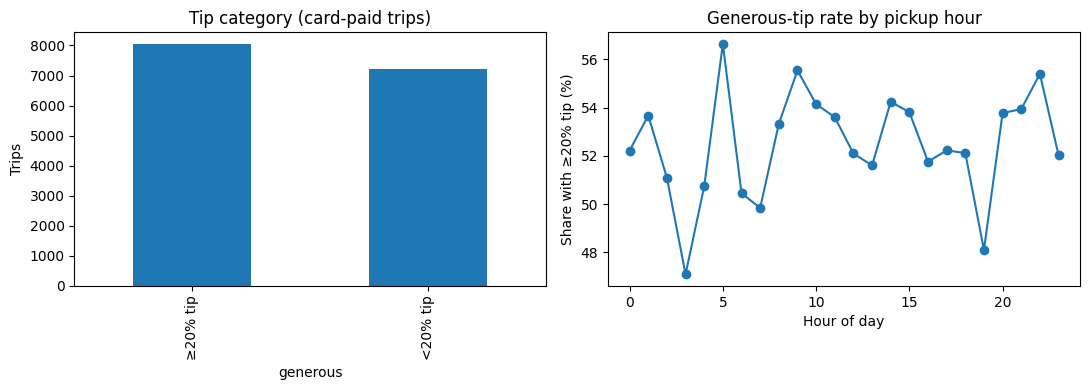

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
work['generous'].map({0:'<20% tip', 1:'≥20% tip'}).value_counts().plot.bar(ax=axes[0], title='Tip category (card-paid trips)')
(work.groupby('pickup_hour')['generous'].mean() * 100).plot(ax=axes[1], marker='o', title='Generous-tip rate by pickup hour')
axes[0].set_ylabel('Trips')
axes[1].set_ylabel('Share with ≥20% tip (%)')
axes[1].set_xlabel('Hour of day')
plt.tight_layout(); plt.show()

## 4. Build a leakage-aware predictive model

Only variables plausibly known **before** trip completion are allowed as predictors. Actual distance, fare, total charges, payment outcome, tip, and drop-off time are intentionally excluded. Pickup/drop-off zone IDs are used as a simplified retrospective assumption: **the trip destination must be known or supplied in advance**. `payment_type` is used for sample selection, not as a predictor.

In [4]:
features = ['VendorID', 'passenger_count', 'PULocationID', 'DOLocationID', 'pickup_hour', 'pickup_day', 'pickup_month']
model_data = work[features + ['generous']].copy()
X = model_data[features]
y = model_data['generous']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.20, random_state=42, stratify=y)
cat = ['VendorID','PULocationID','DOLocationID','pickup_hour','pickup_day','pickup_month']
num = ['passenger_count']
preprocess = ColumnTransformer([
 ('categories', Pipeline([('missing',SimpleImputer(strategy='most_frequent')),('onehot',OneHotEncoder(handle_unknown='ignore'))]),cat),
 ('numbers', SimpleImputer(strategy='median'),num)
])
model = Pipeline([('preprocess',preprocess),('classifier',RandomForestClassifier(n_estimators=120,min_samples_leaf=5,max_depth=12,random_state=42,n_jobs=-1))])
baseline = DummyClassifier(strategy='most_frequent')
model.fit(X_train, y_train)
baseline.fit(X_train, y_train)
print('Train:',X_train.shape,'Test:',X_test.shape)

Train: (12209, 7) Test: (3053, 7)


## 5. Evaluate on held-out data

Both models use the same untouched test split. No test-set tuning is performed. The random forest settings are predefined for this demonstration.

,model,accuracy,precision,recall,f1
0,Majority-class baseline,0.5264,0.5264,1.0000,0.6897
1,Random Forest,0.6931,0.6912,0.7536,0.7210


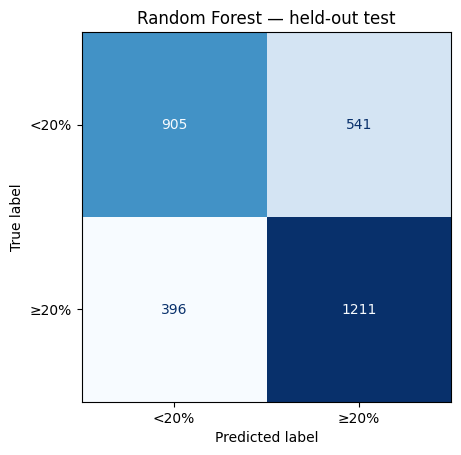

In [5]:
rows=[]
for label, estimator in [('Majority-class baseline',baseline),('Random Forest',model)]:
    pred=estimator.predict(X_test)
    rows.append({'model':label,'accuracy':accuracy_score(y_test,pred),'precision':precision_score(y_test,pred,zero_division=0),'recall':recall_score(y_test,pred,zero_division=0),'f1':f1_score(y_test,pred,zero_division=0)})
metrics = pd.DataFrame(rows)
display(metrics.round(4))
ConfusionMatrixDisplay.from_estimator(model,X_test,y_test,display_labels=['<20%','≥20%'],cmap='Blues',colorbar=False)
plt.title('Random Forest — held-out test');plt.show()

## 6. Interpretation and ethical limitations

- These are **sample-based, retrospective** results. A test score is not proof of readiness for live use.
- Cash tips are unobserved or under-recorded; the sample is limited to card-paid trips.
- The dataset does not establish whether a destination would always have been known when ordering.
- Tip behavior may be influenced by information unavailable before a trip, including service quality.
- **Do not use predictions to refuse service, discriminate, rank individual passengers, or infer personal worth.**
- Next steps: assess temporal generalization, calibration, subgroup performance, and operational feasibility. For a safer deployment use aggregated insights to evaluate service and tipping patterns, rather than individual customer screening.

**Provenance:** Created as an independent, reproducible portfolio adaptation using the supplied 2017 TLC trip sample; the original Coursera lab is preserved separately in `notebooks/original_coursera_lab.ipynb`.